# Exercício de Regressão Linear Simples

O exercício é em uma análise de um banco de dados `state.x77` do _R_ para predição da variável `Assassinato` (`Murder`). A análise consiste de:
1. Obtenção dos dados;
1. Limpeza, avaliação da qualidade;
1. Avaliação visual das medidas;
1. Comparativo das variáveis (_features_) para identificação da variável independente;
1. Regressão da variável resposta `Assassinato` pela variável independente escolhida;
1. Análise dos resultados;
1. Análise dos resíduos;
1. Relatório sobre os resultados.

## Dados

### Carregamento dos dados brutos

In [1]:
st <- as.data.frame(state.x77[, c("Murder","Population","Illiteracy","Income","Frost","HS Grad")])

### Descrição dos atributos

### Resumo dos dados

In [3]:
summary(st)

     Murder         Population      Illiteracy        Income    
 Min.   : 1.400   Min.   :  365   Min.   :0.500   Min.   :3098  
 1st Qu.: 4.350   1st Qu.: 1080   1st Qu.:0.625   1st Qu.:3993  
 Median : 6.850   Median : 2838   Median :0.950   Median :4519  
 Mean   : 7.378   Mean   : 4246   Mean   :1.170   Mean   :4436  
 3rd Qu.:10.675   3rd Qu.: 4968   3rd Qu.:1.575   3rd Qu.:4814  
 Max.   :15.100   Max.   :21198   Max.   :2.800   Max.   :6315  
     Frost           HS Grad     
 Min.   :  0.00   Min.   :37.80  
 1st Qu.: 66.25   1st Qu.:48.05  
 Median :114.50   Median :53.25  
 Mean   :104.46   Mean   :53.11  
 3rd Qu.:139.75   3rd Qu.:59.15  
 Max.   :188.00   Max.   :67.30  

### Importação do _dataset_

In [4]:
x <- as.data.frame(state.x77)

In [5]:
summary(x)

   Population        Income       Illiteracy       Life Exp    
 Min.   :  365   Min.   :3098   Min.   :0.500   Min.   :67.96  
 1st Qu.: 1080   1st Qu.:3993   1st Qu.:0.625   1st Qu.:70.12  
 Median : 2838   Median :4519   Median :0.950   Median :70.67  
 Mean   : 4246   Mean   :4436   Mean   :1.170   Mean   :70.88  
 3rd Qu.: 4968   3rd Qu.:4814   3rd Qu.:1.575   3rd Qu.:71.89  
 Max.   :21198   Max.   :6315   Max.   :2.800   Max.   :73.60  
     Murder          HS Grad          Frost             Area       
 Min.   : 1.400   Min.   :37.80   Min.   :  0.00   Min.   :  1049  
 1st Qu.: 4.350   1st Qu.:48.05   1st Qu.: 66.25   1st Qu.: 36985  
 Median : 6.850   Median :53.25   Median :114.50   Median : 54277  
 Mean   : 7.378   Mean   :53.11   Mean   :104.46   Mean   : 70736  
 3rd Qu.:10.675   3rd Qu.:59.15   3rd Qu.:139.75   3rd Qu.: 81162  
 Max.   :15.100   Max.   :67.30   Max.   :188.00   Max.   :566432  

### Ajuste dos nomes dos atributos

In [6]:
names(st) <- c("Assassinato", "Populacao", "Analfabetismo", "Renda", 
               "Congelamento", "EnsinoMedio")

### Especificação da região

In [7]:
regiao <- c("Sul","Oeste","Oeste","Sul","Oeste","Oeste","Nordeste","Sul","Sul","Sul",
            "Oeste","Oeste","Meio-Oeste","Meio-Oeste","Meio-Oeste","Meio-Oeste","Sul",
            "Sul","Nordeste","Sul","Nordeste","Meio-Oeste","Meio-Oeste","Sul",
            "Meio-Oeste","Oeste","Meio-Oeste","Oeste","Nordeste","Nordeste","Oeste",
            "Nordeste","Sul","Meio-Oeste","Meio-Oeste","Sul","Oeste","Nordeste",
            "Nordeste","Sul","Meio-Oeste","Sul","Sul","Oeste","Nordeste","Sul","Oeste",
            "Sul","Meio-Oeste","Oeste")
st$Regiao <- factor(regiao)

In [8]:
summary(st)

  Assassinato       Populacao     Analfabetismo       Renda     
 Min.   : 1.400   Min.   :  365   Min.   :0.500   Min.   :3098  
 1st Qu.: 4.350   1st Qu.: 1080   1st Qu.:0.625   1st Qu.:3993  
 Median : 6.850   Median : 2838   Median :0.950   Median :4519  
 Mean   : 7.378   Mean   : 4246   Mean   :1.170   Mean   :4436  
 3rd Qu.:10.675   3rd Qu.: 4968   3rd Qu.:1.575   3rd Qu.:4814  
 Max.   :15.100   Max.   :21198   Max.   :2.800   Max.   :6315  
  Congelamento     EnsinoMedio           Regiao  
 Min.   :  0.00   Min.   :37.80   Meio-Oeste:12  
 1st Qu.: 66.25   1st Qu.:48.05   Nordeste  : 9  
 Median :114.50   Median :53.25   Oeste     :13  
 Mean   :104.46   Mean   :53.11   Sul       :16  
 3rd Qu.:139.75   3rd Qu.:59.15                  
 Max.   :188.00   Max.   :67.30                  

## Análise Exploratória

In [10]:
# criando função para dimensionar gráfico no Jupyter
library(repr)
grafdim <- function(x=11,y=9) { options(repr.plot.width=x, repr.plot.height=y) }

O primeiro passo seria uma avaliação visual do comportamento da variáveis, identificar possíveis valores atípicos (_outliers_) e anormalidades de registro ou medição.

### Gráficos de _Boxplot_

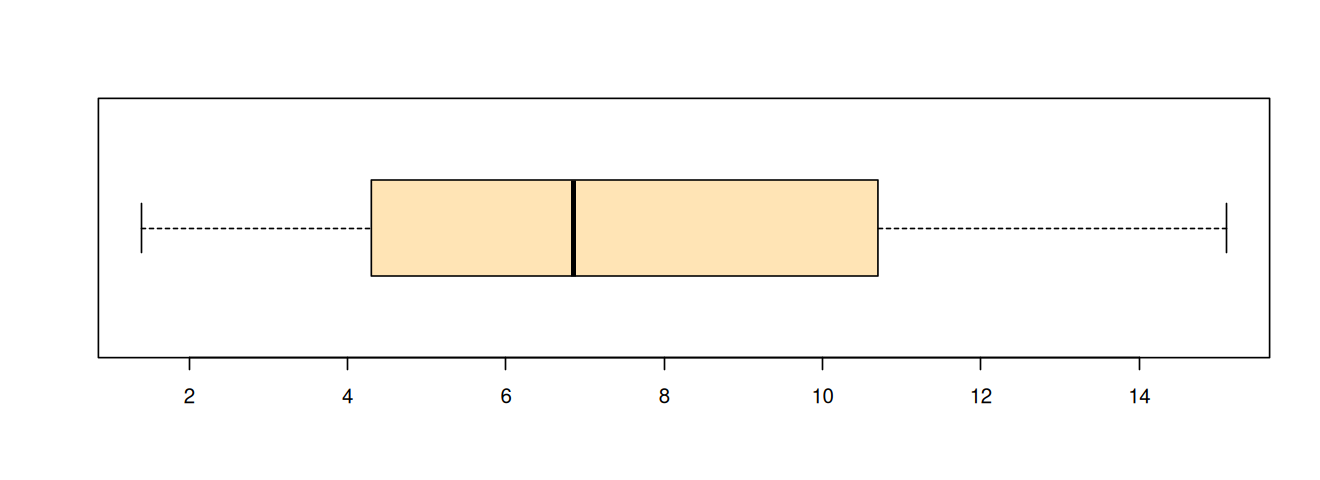

In [14]:
grafdim(11,4)
boxplot(st$Assassinato, horizontal=TRUE, col="moccasin")

In [15]:
ncol(st)

[1] 7

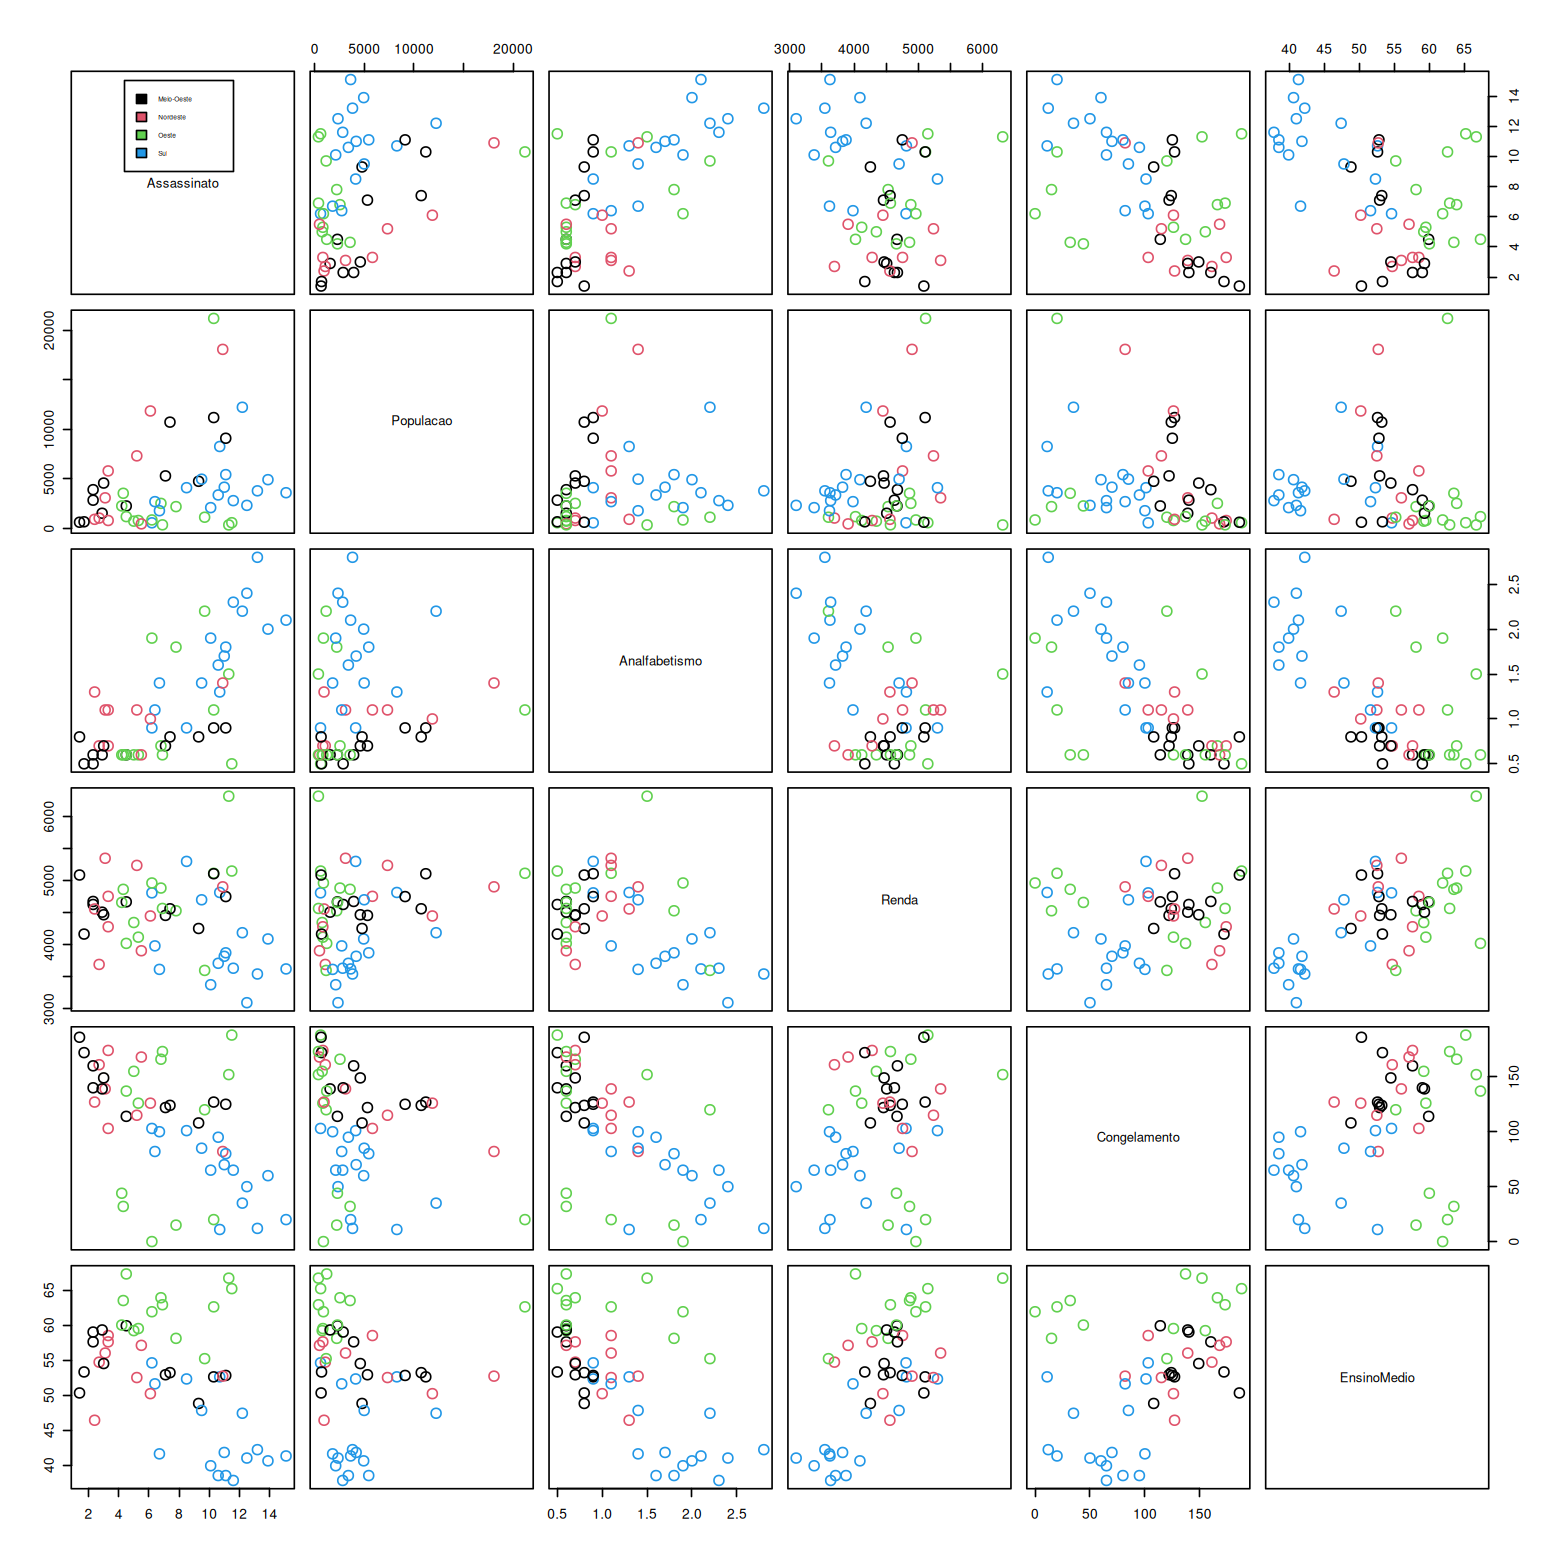

In [16]:
grafdim(13,13)
reg <- c(sort(levels(st$Regiao)))
pairs(st[,1:6], col=st$Regiao, cex=1.5)
par(xpd=TRUE)
legend(0.05,0.98, fill=sort(unique(st$Regiao)), legend=c(sort(levels(st$Regiao))), cex=0.3)

In [1]:
# definindo como calcular o erro absoluto médio:
eam <- function (predito, observado) {
    if (length(predito) == length(observado)) {
        resultado <- sum(abs(predito - observado)) / length(observado)
        return (resultado)
    } else { 
        return (NA) 
    }
}

In [16]:
# definindo como calcular o erro quadrático médio:
eqm <- function (predito, observado) {
    if (length(predito) == length(observado)) {
        diferenca <- predito - observado
        resultado <- sum(diferenca * diferenca) / length(observado)
        return (resultado)
    } else { 
        return (NA) 
    }
}